## Reset → X → delay → measurement: target from scratch

This self-contained example maps logical qubit 0 to physical **q1**. We build every pulse template, register the three operations, and supply calibration values explicitly without using a default registry. Values are illustrative; hardware execution requires device calibration. Durations are in seconds and frequencies in Hz.


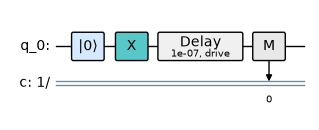

In [ ]:
from mb_client.circuit import QuantumCircuit, Reset, XGate, Measure
from mb_client.common import Parameter
from mb_client.compilation import CalibrationParams, InstSchedRegistry, Target, schedule
from mb_client.pulse import (
    PulseSequence, Pulse, NetZero, Idle, Drag, ErrorFunction,
    FluxChannel, DriveChannel, ReadoutChannel,
)

%matplotlib inline

simple_circuit = QuantumCircuit(1, 1, name="reset_x_delay_measure")
simple_circuit.physical_qubits = (1,)
simple_circuit.reset(0)
simple_circuit.x(0)
simple_circuit.delay(100e-9, 0, channel="drive")
simple_circuit.measure(0, 0)
simple_circuit.draw(format="mpl")


### Define symbolic pulse templates

Template channel index 0 refers to the operation's first operand, not physical q0. Registration will map it to q1. The same parameter names can have different calibration values for each gate.

Reset uses a flux pulse followed by a settling interval. X uses a DRAG pulse. Measurement plays a readout pulse and acquires on independent lanes, so playback and acquisition begin together. The compiler supplies the circuit's destination classical bit.


In [2]:
duration = Parameter("duration", group="calibration")
amplitude = Parameter("amplitude", group="calibration")
sigma = Parameter("sigma", group="calibration")
post_pad = Parameter("post_pad", group="calibration")
beta = Parameter("beta", group="calibration")
frequency = Parameter("frequency", group="calibration")

with PulseSequence(template=True) as reset_template:
    reset_template.play(FluxChannel(0), Pulse(NetZero(duration, amplitude, sigma)))
    reset_template.barrier(FluxChannel(0), DriveChannel(0))
    reset_template.play(DriveChannel(0), Pulse(Idle(post_pad)))

with PulseSequence(template=True) as x_template:
    x_template.play(
        DriveChannel(0), Pulse(Drag(duration, amplitude, beta), frequency=frequency)
    )

with PulseSequence(template=True) as measure_template:
    measure_template.play(
        ReadoutChannel(0),
        Pulse(ErrorFunction(duration, amplitude, sigma), frequency=frequency),
    )
    measure_template.acquire(ReadoutChannel(0), duration, demod_freq=frequency)


### Register operations and supply calibration values

Start with an empty registry for physical q1. Delay needs no registration: the compiler lowers it to a pulse delay. These templates have no parameter defaults, so all required values are provided below.


In [3]:
simple_registry = InstSchedRegistry([1])
simple_registry.add(Reset(), (1,), reset_template)
simple_registry.add(XGate(), (1,), x_template)
simple_registry.add(Measure(), (1,), measure_template)

calibration_values = {
    "reset": {"duration": 200e-9, "amplitude": 0.2, "sigma": 10e-9, "post_pad": 40e-9},
    "x": {"duration": 40e-9, "amplitude": 0.1, "beta": 0.0, "frequency": 5e9},
    "measure": {"duration": 1e-6, "amplitude": 0.1, "sigma": 10e-9, "frequency": 6.5e9},
}
simple_calibrations = CalibrationParams()
for gate_name, values in calibration_values.items():
    for parameter_name, value in values.items():
        simple_calibrations = simple_calibrations.set(
            qubit=(1,), gate=gate_name, parameter=parameter_name, value=value
        )

simple_target = Target(
    inst_sched_reg=simple_registry,
    calibration_params=simple_calibrations,
)


### Compile and plot the pulse schedule

`schedule()` compiles the circuit directly into a `PulseSchedule`, resolving calibrated templates and assigning pulse start times in one call. `ordering="gate"` synchronizes channels at instruction boundaries, preserving reset → X → delay → measurement across flux, drive, and readout channels.

With these values, reset and settling finish at 240 ns, X finishes at 280 ns, and readout and acquisition start after the 100 ns delay at 380 ns.


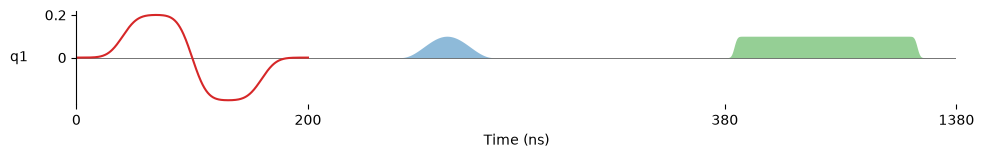

In [4]:
compiled_schedule = schedule(
    simple_circuit, target=simple_target, ordering="gate"
)
figure_compiled, axes_compiled = compiled_schedule.draw()
